# La banda de incertidumbre de dependencia y las cotas de VaR del peor caso

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (la suma simple, la regla de la raíz cuadrada y las cópulas)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué el VaR comonotónico, el VaR de riesgos perfectamente dependientes, no es el peor caso, y calcular el peor y el mejor VaR exactos de una suma para marginales conocidas y cualquier dependencia con el algoritmo de reordenamiento;
- ver trabajar al algoritmo de reordenamiento sobre una matriz lo bastante pequeña para imprimirla, y entender por qué termina con sumas de fila casi iguales;
- construir la **banda** del caso, la cota inferior, la suma simple, la regla de la raíz cuadrada, la cópula gaussiana, una cópula t por cada grado de libertad y el peor caso, y decir cuáles de sus filas dependen de la matriz de correlación y cuáles no;
- comprobar las reglas estructurales de la banda con la prueba `worst_case_bracket` del motor, y leer cómo el estrés de la correlación mercado-crédito mueve la banda versionada;
- explicar por qué el caso muestra la banda completa junto al capital principal y nunca una sola cifra diversificada.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee el mismo caso de los cuadernos 01 y 02, **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginales, matriz, banda versionada), `data/derived/C18/t-copula-baseline.json` (`outputs.correlation_stress`: la misma banda con la correlación mercado-crédito subida a 0,8) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`, las funciones de cuantiles de las marginales).
- **Las marginales se reconstruyen desde las grillas de cuantiles versionadas en los pasos simulados.** Igual que en el cuaderno 02, el documento de modelos tiene la función de cuantiles de cada marginal sobre una grilla nombrada y no las pérdidas simuladas, así que el paso 3 reconstruye las cuatro marginales desde ella y corre la banda sobre ellas con los ajustes del pipeline; se espera recuperar la banda versionada con error menor que 0,01 por ciento. Los pasos 1 y 2 usan en cambio un ejemplo publicado con marginales en forma cerrada, para poder comprobar el algoritmo contra una fórmula.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
stress = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
print("filas de la banda versionada:", len(agg["band"]), "| horneado con riskvalidation", baseline["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

carpeta derived encontrada: sí
filas de la banda versionada: 8 | horneado con riskvalidation 0.8.1 | instalado 0.8.1


## Método

### Paso 1: el VaR comonotónico no es el peor caso

Cuando la dependencia entre los riesgos es desconocida, una cota superior natural pero errada es el **VaR comonotónico**, el VaR de la suma cuando los riesgos se mueven juntos de forma perfecta: $\mathrm{VaR}_q(L_1 + \dots + L_d) = \sum_k F_k^{-1}(q)$. Es la suma simple de los VaR, exacta para dependencia perfecta. Pero **el VaR no es subaditivo**, así que alguna otra dependencia puede dar un VaR de la suma mayor (Embrechts, McNeil y Straumann 2002; Embrechts, Puccetti y Rueschendorf 2013). El motor calcula el mejor y el peor VaR exactos sobre todas las estructuras de dependencia, dadas solo las marginales.

El ejemplo publicado de Embrechts, Puccetti y Rueschendorf (2013, Tabla 4) usa marginales Pareto(2), $F(x) = 1 - (1+x)^{-2}$, de modo que $F^{-1}(q) = (1-q)^{-1/2} - 1$ en forma cerrada, con $d = 8$ riesgos. La celda siguiente construye las ocho funciones de cuantiles, evalúa el VaR comonotónico en $q = 0,99$ con `comonotonic_var` y por la forma cerrada, y luego calcula el peor y el mejor VaR con `worst_var_bounds` ($N = 10^5$ celdas, $\epsilon = 10^{-3}$, los ajustes del pipeline).

In [3]:
# Ocho marginales Pareto(2) del ejemplo publicado: VaR comonotónico por el motor y por la fórmula, y luego las cotas exactas
def pareto_ppf(u):
    # la función de cuantiles de F(x) = 1 - (1 + x)^-2; la última celda de la grilla es exactamente 1, donde el cuantil es +infinito
    with np.errstate(divide="ignore"):
        return (1.0 - np.asarray(u, dtype=float)) ** -0.5 - 1.0


D, Q = 8, 0.99
pareto = [pareto_ppf] * D
print("VaR comonotónico, motor:", round(bounds.comonotonic_var(pareto, Q), 4), "| forma cerrada d * ((1 - q)^(-1/2) - 1):", round(D * ((1 - Q) ** -0.5 - 1), 4))
sharp = bounds.worst_var_bounds(pareto, Q, 100_000, 1e-3, seed=0)
print("mejor VaR (rango inferior):", np.round(sharp.lower_range, 3), "| peor VaR (rango superior):", np.round(sharp.upper_range, 3))
print("barridos de las cuatro corridas:", sharp.sweeps, "| convergió:", sino(sharp.converged))
print("peor VaR sobre el VaR comonotónico:", round(sharp.upper_range[1] / bounds.comonotonic_var(pareto, Q), 3))

VaR comonotónico, motor: 72.0 | forma cerrada d * ((1 - q)^(-1/2) - 1): 72.0
mejor VaR (rango inferior): [8.995 9.   ] | peor VaR (rango superior): [141.663 141.669]
barridos de las cuatro corridas: (4, 4, 5, 5) | convergió: sí
peor VaR sobre el VaR comonotónico: 1.968


### Paso 2: cómo funciona el algoritmo de reordenamiento

El peor VaR es el mayor valor que puede tomar la **menor** suma de fila. Se toma el $1 - q$ superior de cada marginal, se corta en $N$ celdas y se ponen los cuantiles de las celdas en una matriz $X$ de $N$ filas y $d$ columnas. Toda dependencia en la cola es una permutación de cada columna. El **algoritmo de reordenamiento** (Embrechts, Puccetti y Rueschendorf 2013, sección 2.2) busca la permutación que hace las sumas de fila lo más iguales posible: permuta las columnas al azar y luego, una columna a la vez, la reordena **de forma opuesta** a la suma de las otras (el valor mayor junto al menor resto), y repite hasta que la menor suma de fila cambia en menos de $\epsilon$. Igualar todas las sumas de fila es la "mezclabilidad conjunta" que da el peor caso: ninguna fila queda con un total pequeño.

La celda siguiente lo muestra en una matriz lo bastante pequeña para imprimirla: tres riesgos con la marginal Pareto(2), $N = 10$ celdas sobre $[0,99; 1]$ tomadas en sus puntos medios. Imprime las sumas de fila del arreglo comonotónico (todas las columnas ordenadas igual) y de la matriz reordenada.

In [4]:
# Una matriz de 10 x 3 cuantiles de celda: las sumas de fila comonotónicas y las reordenadas
cells = 10
midpoints = Q + (1 - Q) * (np.arange(cells) + 0.5) / cells
column = pareto_ppf(midpoints)
matrix = np.column_stack([column] * 3)
print("cuantiles de celda de una columna:", np.round(column, 2))
print("sumas de fila comonotónicas:", np.round(matrix.sum(axis=1), 1), "| la menor:", round(matrix.sum(axis=1).min(), 2))
rearranged, value, sweeps, converged = bounds.rearrangement_algorithm(matrix, "max-min-row-sum", 1e-3, 1000, 0)
print("sumas de fila reordenadas  :", np.round(rearranged.sum(axis=1), 1), "| la menor:", round(value, 2))
print("barridos:", sweeps, "| convergió:", sino(converged), "| mismos valores en cada columna:", sino(np.allclose(np.sort(rearranged, axis=0), np.sort(matrix, axis=0))))

cuantiles de celda de una columna: [ 9.26  9.85 10.55 11.4  12.48 13.91 15.9  19.   24.82 43.72]
sumas de fila comonotónicas: [ 27.8  29.5  31.6  34.2  37.5  41.7  47.7  57.   74.5 131.2] | la menor: 27.78
sumas de fila reordenadas  : [45.4 46.8 62.8 45.4 46.8 46.8 62.8 47.4 45.7 62.8] | la menor: 45.39
barridos: 3 | convergió: sí | mismos valores en cada columna: sí


El reordenamiento solo mueve valores dentro de cada columna, así que las marginales no cambian, y la menor suma de fila sube desde el valor comonotónico a uno mucho mayor. Ese es el mecanismo por el que una estructura de dependencia puede pedir mucho más capital que la suma de dependencia perfecta: **reparte las pérdidas extremas entre escenarios** de modo que todo escenario sea malo.

### Paso 3: las marginales de Banco Andino

Para las cuatro marginales del caso el documento de modelos tiene las funciones de cuantiles sobre la grilla nombrada del cuaderno 02 (1.961 probabilidades, lineales en la probabilidad entre puntos y fijas en los extremos). La celda de abajo las reconstruye, lee de cada una una muestra de $10^6$ posiciones de Hazen e imprime el VaR que lee el motor junto al versionado.

In [5]:
# Reconstruir las cuatro marginales desde las grillas de cuantiles versionadas y comparar el VaR que lee el motor con el versionado
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
el = np.array([m["el_clp_m"] for m in agg["marginals"]])
for m in agg["marginals"]:
    print(f'{m["risk"]:12s} VaR que lee el motor {rv_port.var_from_sample(samples[m["risk"]], LEVEL):10,.0f} | versionado {m["var_clp_m"]:10,.0f}')
print("VaR comonotónico de las cuatro marginales menos la suma de las EL:", round(bounds.comonotonic_var(ppfs, LEVEL) - el.sum(), 1), "| suma simple versionada:", round(simple.simple_sum(ec), 1))

credit       VaR que lee el motor    298,239 | versionado    298,227
market       VaR que lee el motor    283,436 | versionado    283,435
irrbb        VaR que lee el motor    100,747 | versionado    100,746
operational  VaR que lee el motor     42,357 | versionado     42,367
VaR comonotónico de las cuatro marginales menos la suma de las EL: 658130.3 | suma simple versionada: 658046.0


### Paso 4: la banda

`dependence_band` pone todo sobre las mismas marginales, un horizonte y un nivel de confianza, y devuelve la **banda**, nunca una sola cifra diversificada:

| Fila | Cómo se calcula | ¿Depende de la matriz? |
|---|---|---|
| cota inferior | el mejor VaR de `worst_var_bounds` (su `lower_range[0]`) menos la suma de las pérdidas esperadas; con signo | no |
| suma simple | $\sum_k EC_k$, el capital **principal** | no |
| varianza-covarianza | $\sqrt{EC^{\top} R\, EC}$ | sí |
| cópula gaussiana | `copula_aggregate` | sí |
| cópula t, una fila por $\nu$ | `copula_aggregate` | sí |
| peor caso | el peor VaR de `worst_var_bounds` (su `upper_range[1]`) menos la suma de las pérdidas esperadas | no |

Cada fila es capital económico en la base $EC = \mathrm{VaR} - \mathrm{EL}$; la suma simple tiene el estado `headline-capital` y toda otra fila `information-not-capital`, de modo que una cifra diversificada no se confunde con el capital. Una fila sobre el capital principal es un resultado verdadero y lo informa la prueba de signo, nunca se repara. La celda siguiente corre la banda con los ajustes del pipeline (un millón de simulaciones, $10^5$ celdas de cota, semilla 42) y la imprime junto a la versionada.

In [6]:
# Correr toda la banda sobre las marginales reconstruidas desde las grillas versionadas con los ajustes del pipeline e imprimirla junto a la banda versionada
band = rv_band.dependence_band(ppfs, ec, el, R, NU_SET, level=LEVEL, horizon_years=1, n_draws=1_000_000, seed=42,
                               chunk_size=100_000, bounds_n=100_000, bounds_epsilon=1e-3, ec_consistency_tolerance=0.01)
print("capital principal:", round(band.headline, 1), "| base:", band.capital_basis, "| horizonte:", band.horizon_years, "| nivel:", band.confidence_level)
print(f'{"método":20s} {"nu":>4s} {"aquí":>10s} {"versionado":>10s} {"DF aquí":>8s} {"estado":24s}')
for row in band.rows:
    other = committed[(row.method, row.nu)]
    print(f'{row.method:20s} {"-" if row.nu is None else format(row.nu, "g"):>4s} {row.capital:10,.0f} {other["capital_clp_m"]:10,.0f} {row.diversification_factor:8.4f} {row.status:24s}')

capital principal: 658046.0 | base: economic-capital-var-less-el | horizonte: 1 | nivel: 0.999
método                 nu       aquí versionado  DF aquí estado                  
lower-bound             -    118,509    118,518   0.1801 information-not-capital 
simple-sum              -    658,046    658,046   1.0000 headline-capital        
variance-covariance     -    528,106    528,106   0.8025 information-not-capital 
gaussian-copula         -    491,999    491,974   0.7477 information-not-capital 
t-copula                4    552,369    552,389   0.8394 information-not-capital 
t-copula                8    528,318    528,321   0.8029 information-not-capital 
t-copula               30    499,133    499,128   0.7585 information-not-capital 
worst-case              -    823,347    823,332   1.2512 information-not-capital 


Tres cosas para leer en la tabla. La suma simple y la fila de raíz cuadrada son iguales a las versionadas al dígito, porque solo usan los capitales versionados. Las dos cotas salen de las marginales reconstruidas y caen sobre las versionadas: el peor caso 823.347 frente a 823.332 y la cota inferior 118.509 frente a 118.518, con error menor que 0,01 por ciento. La cota inferior depende del cuerpo de las distribuciones y el peor caso de sus colas sobre el cuantil 99,9 por ciento, y las grillas versionadas llevan ambos. Las filas con cópula son las del cuaderno 02.

### Paso 5: la regla estructural de la banda

Sean cuales sean las marginales, la cota inferior es el mejor VaR posible de la suma sobre toda estructura de dependencia y el peor caso es el peor posible, y por lo tanto **toda otra fila de la banda queda entre ellos**. La prueba `worst_case_bracket` del motor lo comprueba: roja si alguna fila queda fuera de $[\text{inferior}, \text{peor}]$, verde en otro caso, con el estadístico peor menos inferior y la métrica ese rango sobre la mayor fila. La celda siguiente la corre sobre la banda versionada, sobre la banda de este cuaderno y sobre una banda en que se empujó una fila fuera a propósito.

In [7]:
# Correr la prueba del intervalo sobre la banda versionada, sobre la banda de este cuaderno y sobre una banda con una fila empujada fuera
def bracket_of(rows):
    capitals = {(r["method"], r["nu"]): r["capital_clp_m"] for r in rows}
    between = [v for (method, nu), v in capitals.items() if method not in ("lower-bound", "worst-case")]
    return capitals[("lower-bound", None)], between, capitals[("worst-case", None)]


mine = [{"method": r.method, "nu": r.nu, "capital_clp_m": r.capital} for r in band.rows]
pushed = [dict(r, capital_clp_m=r["capital_clp_m"] * 2.0) if r["method"] == "gaussian-copula" else r for r in agg["band"]]
for label, rows in (("banda versionada", agg["band"]), ("este cuaderno", mine), ("una fila fuera", pushed)):
    lower, between, worst = bracket_of(rows)
    result = agg_tests.worst_case_bracket(lower, between, worst)
    print(f"{label:17s} luz: {result.light.value:5s} | peor - inferior: {result.statistic:10,.0f} | rango sobre la mayor fila: {result.metric:.4f} | filas fuera: {result.extras['rows_outside']}")

banda versionada  luz: green | peor - inferior:    704,814 | rango sobre la mayor fila: 1.0711 | filas fuera: 0
este cuaderno     luz: green | peor - inferior:    704,838 | rango sobre la mayor fila: 1.0711 | filas fuera: 0
una fila fuera    luz: red   | peor - inferior:    704,814 | rango sobre la mayor fila: 0.7163 | filas fuera: 1


### Paso 6: qué mueve el estrés de la correlación

El caso vuelve a correr la banda con la correlación mercado-crédito subida de 0,5 a 0,8, el extremo superior de los rangos publicados (dossier 05, G.5). Las tres filas que no dependen de la matriz no pueden moverse; las tres clases que sí dependen, se moverán. La prueba `correlation_stress` del motor lee el cambio de la fila gaussiana frente a un umbral ámbar. La celda siguiente lee la banda con estrés que versionó el pipeline, recalcula la fila de raíz cuadrada con la matriz con estrés usando el motor e imprime el cambio de cada fila.

In [8]:
# Leer la banda con estrés, recalcular su fila de raíz cuadrada con el motor e imprimir cómo cambió cada fila
R_stress = np.array(stress["aggregation"]["correlation"]["matrix"])
print("par con estrés:", stress["pair"], "| matriz válida:", sino(simple.check_correlation(R_stress) is None))
stressed = {(r["method"], r["nu"]): r for r in stress["aggregation"]["band"]}
print("varianza-covarianza con la matriz con estrés (motor):", round(simple.variance_covariance(ec, R_stress), 1), "| versionado:", round(stressed[("variance-covariance", None)]["capital_clp_m"], 1))
gauss_test = agg_tests.correlation_stress(committed[("gaussian-copula", None)]["capital_clp_m"], stressed[("gaussian-copula", None)]["capital_clp_m"])
print("prueba del motor correlation_stress sobre las filas gaussianas: luz", gauss_test.light.value, "| cambio:", round(gauss_test.statistic, 4), "| umbral ámbar:", gauss_test.extras["thresholds"]["amber"])
print(f'{"método":20s} {"nu":>4s} {"base":>10s} {"con estrés":>10s} {"cambio":>8s}')
for key, row in committed.items():
    after = stressed[key]["capital_clp_m"]
    print(f'{key[0]:20s} {"-" if key[1] is None else format(key[1], "g"):>4s} {row["capital_clp_m"]:10,.0f} {after:10,.0f} {after / row["capital_clp_m"] - 1:8.1%}')

par con estrés: {'a': 'market', 'b': 'credit', 'value': 0.8} | matriz válida: sí
varianza-covarianza con la matriz con estrés (motor): 568520.5 | versionado: 568520.5
prueba del motor correlation_stress sobre las filas gaussianas: luz amber | cambio: 0.1211 | umbral ámbar: 0.1
método                 nu       base con estrés   cambio
lower-bound             -    118,518    118,518     0.0%
simple-sum              -    658,046    658,046     0.0%
variance-covariance     -    528,106    568,521     7.7%
gaussian-copula         -    491,974    551,569    12.1%
t-copula                4    552,389    587,531     6.4%
t-copula                8    528,321    577,065     9.2%
t-copula               30    499,128    557,223    11.6%
worst-case              -    823,332    823,332     0.0%


## Resultados

El gráfico dibuja la banda versionada con la matriz base y con la matriz con estrés. La suma simple, la cota inferior y el peor caso son iguales en ambas, las otras se mueven a la derecha, y toda fila queda dentro del intervalo.

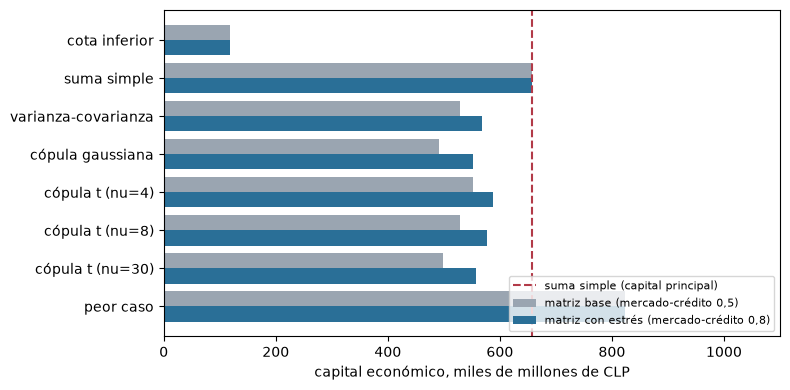

In [9]:
# Dibujar la banda versionada con la matriz de correlación base y con estrés, con el capital principal como línea vertical
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple", "variance-covariance": "varianza-covarianza",
         "gaussian-copula": "cópula gaussiana", "t-copula": "cópula t", "worst-case": "peor caso"}
keys = list(committed)
labels = [NAMES[k[0]] + (f" (nu={k[1]:g})" if k[1] else "") for k in keys]
y = np.arange(len(keys))[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y + 0.2, [committed[k]["capital_clp_m"] / 1e3 for k in keys], height=0.4, color="#9aa5b1", label="matriz base (mercado-crédito 0,5)")
ax.barh(y - 0.2, [stressed[k]["capital_clp_m"] / 1e3 for k in keys], height=0.4, color="#2a6f97", label="matriz con estrés (mercado-crédito 0,8)")
ax.axvline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="suma simple (capital principal)")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_xlim(0, 1100)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

- **El VaR comonotónico del ejemplo publicado es 72,0, igual a su fórmula, y el peor VaR es 141,66 a 141,67, 1,97 veces mayor** (el mejor VaR es 9,00): las corridas de reordenamiento convergieron en 4 a 5 barridos. La dependencia perfecta está lejos del peor caso.
- **El reordenamiento sube la menor suma de fila de la matriz pequeña de 27,8 a 45,4** y lleva las sumas de fila a un rango estrecho (45,4 a 62,8, frente a 27,8 a 131,2), sin cambiar los valores de ninguna columna.
- **Sobre las marginales reconstruidas toda fila de la banda vuelve.** La suma simple y la fila de raíz cuadrada son iguales a las versionadas (658.046 y 528.106 millones de CLP), porque usan solo los capitales versionados. La cota inferior es 118.509 frente a 118.518 y el peor caso 823.347 frente a 823.332, ambos con error menor que 0,01 por ciento, y las filas gaussiana y t son las del cuaderno 02 (491.999 frente a 491.974 en la cópula gaussiana).
- **La regla estructural se cumple donde debe.** `worst_case_bracket` es verde en la banda versionada (peor menos inferior 704.814, 1,0711 veces la mayor fila) y en la banda de este cuaderno (704.838, 1,0711 veces), y roja cuando se duplica la fila gaussiana fuera del intervalo (una fila fuera).
- **El estrés de la correlación mueve solo las filas que usan la matriz.** Con mercado-crédito 0,8 la fila de raíz cuadrada sube 7,7 por ciento (a 568.521, que el motor recalcula con la matriz con estrés), la fila gaussiana 12,1 por ciento y las filas t 6,4; 9,2 y 11,6 por ciento para $\nu = 4$, 8 y 30; la cota inferior, la suma simple y el peor caso no se mueven nada. La prueba `correlation_stress` del motor lee el cambio gaussiano, 12,11 por ciento, frente a su umbral de 10 por ciento y se pone ámbar.

Lo que este cuaderno no muestra: las muestras de un millón de simulaciones, que no están versionadas, así que las marginales salen de una grilla de 1.961 puntos y las filas coinciden hasta 0,01 por ciento y no hasta el dígito; y un peor caso calculado sobre marginales es exacto solo en la medida en que las marginales sean correctas en su cola superior, aquí hasta el alcance de la grilla, 4,8e-7 del extremo.

## Resumen

- El VaR comonotónico es el VaR de riesgos perfectamente dependientes y no es el peor caso, porque un VaR no es subaditivo; el algoritmo de reordenamiento da el mejor y el peor VaR exactos para marginales conocidas y cualquier dependencia.
- El algoritmo solo permuta valores dentro de cada columna y apunta a sumas de fila iguales, lo que reparte los extremos de modo que todo escenario sea malo.
- La banda muestra, sobre las mismas marginales, horizonte y nivel, la cota inferior, la suma simple (el capital principal), la regla de la raíz cuadrada, la cópula gaussiana, una cópula t por grado de libertad y el peor caso, cada una rotulada principal o información.
- Las cotas y la suma simple no dependen de la matriz de correlación; las otras filas sí, y la matriz es una convención.
- Toda fila queda dentro del intervalo, que `worst_case_bracket` comprueba y pone en rojo cuando falla.

**Qué probar a continuación.** Cambia `bounds_n` en el paso 4 a 10.000 y mira cuánto se mueve el peor caso; luego sigue con el cuaderno 04, que convierte los escenarios macro en las tasas de pérdida que alimentan la marginal de crédito.

## Referencias

- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (la banda, las cotas y las pruebas de validación).